Model downloaded successfully!
Classes: ['bacterial blight', 'curl virus', 'fussarium wilt', 'healthy']

Disease Classes:
0 -> bacterial blight
1 -> curl virus
2 -> fussarium wilt
3 -> healthy

DenseNet-121 model loaded successfully!

Upload a cotton leaf image:


Saving cotton blight.jpg to cotton blight.jpg


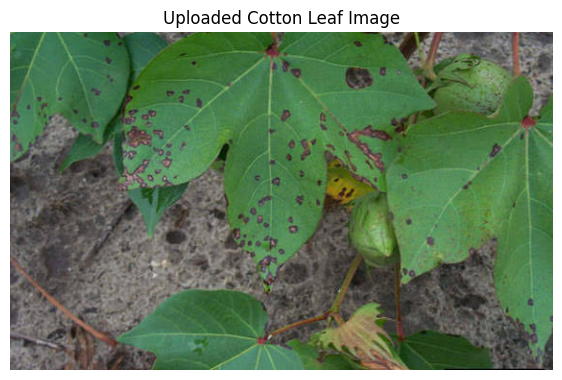


          COTTON LEAF PREDICTION

Predicted Disease : bacterial blight
Confidence        : 88.80%

All Class Probabilities:
bacterial blight     : 88.80%
curl virus           : 0.96%
fussarium wilt       : 6.75%
healthy              : 3.49%


In [9]:
# ============================================================
# COTTON LEAF DISEASE PREDICTION
# Hugging Face Model: FarmGuard/cotton-densenet121
# Google Colab - Single Cell
# ============================================================

# -------------------
# 1. Install required libraries
# -------------------
!pip -q install huggingface_hub torch torchvision pillow matplotlib

# -------------------
# 2. Import libraries
# -------------------
import torch
import torch.nn.functional as F
import torchvision.models as models
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files
import json
import os

# -------------------
# 3. Download model files
# -------------------
from huggingface_hub import hf_hub_download

REPO_ID = "FarmGuard/cotton-densenet121"

# Download model weights (fixed filename to best_densenet.pth based on repo file list)
model_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="best_densenet.pth"
)

# Download class labels
classes_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="classes.json"
)

print("Model downloaded successfully!")

# -------------------
# 4. Load class names
# -------------------
with open(classes_path, "r") as f:
    classes_data = json.load(f)

print("Classes:", classes_data)

# Handle possible JSON formats
if isinstance(classes_data, list):
    class_names = classes_data

elif isinstance(classes_data, dict):
    # If JSON is {"0": "bacterial blight", ...}
    class_names = [
        classes_data[str(i)]
        for i in range(len(classes_data))
    ]

else:
    raise ValueError("Unknown classes.json format")

print("\nDisease Classes:")
for i, name in enumerate(class_names):
    print(i, "->", name)

# -------------------
# 5. Create DenseNet-121 model
# -------------------
model = models.densenet121(weights=None)

# Replace final classifier for 4 classes
model.classifier = torch.nn.Linear(
    model.classifier.in_features,
    len(class_names)
)

# -------------------
# 6. Load trained weights
# -------------------
checkpoint = torch.load(
    model_path,
    map_location="cpu"
)

# Handle nested model_state_dict structure in training checkpoints
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

# Remove "module." prefix if present
new_state_dict = {}

for key, value in state_dict.items():
    new_key = key.replace("module.", "")
    new_state_dict[new_key] = value

model.load_state_dict(new_state_dict)

# Evaluation mode
model.eval()

print("\nDenseNet-121 model loaded successfully!")

# -------------------
# 7. Image preprocessing
# -------------------
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# -------------------
# 8. Upload cotton leaf image
# -------------------
print("\nUpload a cotton leaf image:")

uploaded = files.upload()

image_file = list(uploaded.keys())[0]

# Open image
image = Image.open(image_file).convert("RGB")

# -------------------
# 9. Display uploaded image

# -------------------
plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Cotton Leaf Image")
plt.show()

# -------------------
# 10. Preprocess image
# -------------------
input_tensor = transform(image)
input_batch = input_tensor.unsqueeze(0)

# -------------------
# 11. Make prediction
# -------------------
with torch.no_grad():
    outputs = model(input_batch)

# Convert logits to probabilities
probabilities = F.softmax(outputs, dim=1)[0]

# Get predicted class
predicted_index = torch.argmax(probabilities).item()
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index].item() * 100

# -------------------
# 12. Display prediction
# -------------------
print("\n" + "=" * 50)
print("          COTTON LEAF PREDICTION")
print("=" * 50)

print(f"\nPredicted Disease : {predicted_class}")
print(f"Confidence        : {confidence:.2f}%")

print("\nAll Class Probabilities:")

for i, probability in enumerate(probabilities):
    print(
        f"{class_names[i]:20s} : "
        f"{probability.item() * 100:.2f}%"
    )

print("=" * 50)

